Project Name : Strava EDA Analysis

In [ ]:
Project Type - EDA 
Contribution - Individual
Name - Sanketh S

# **Project Summary -**

Strava, Inc. is a US-based company that operates a popular fitness tracking and social networking app, primarily for cyclists and runners. Founded in 2009 by Mark Gainey and Michael Horvath, Strava allows users to record physical activities using GPS data, analyze performance metrics, and share their results with a community of athletes. The platform supports various sports and integrates with many fitness devices. Strava is known for features such as leaderboards, challenges, and competition, which promote motivation. The company is headquartered in San Francisco, California.

# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**


We have multiple datasets to study the activities of a person using Strava. We need to merge all the datasets into one, analyze the data, and provide suitable solutions for the business problems.

#### **Define Your Business Objective?**

The business objective for Strava datasets are as follows:
1. To analyze the datataset and find new trends which attracts more customers to download the app.
2. To analyze the datataset and find how to attract the users to use subscription model.
3. To analyze the datataset and find the insights for the activities and analyze the behaviour and pattern based on it.
4. To analyze the datataset and find the choices and feedback of customers while using the app.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import missingno as ms

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import plotly.express as px
import random

from wordcloud import WordCloud
import ast

from PIL import Image
from IPython.display import display
import statsmodels.api as stat
import geopandas as geo

### Dataset Loading

In [6]:
# Load Dataset

dataset1 = pd.read_csv("dailyActivity_merged.csv")
dataset2 = pd.read_csv("dailyCalories_merged.csv")
dataset3 = pd.read_csv("dailyIntensities_merged.csv")
dataset4 = pd.read_csv("dailySteps_merged.csv")
dataset5 = pd.read_csv("sleepDay_merged.csv")
dataset6 = pd.read_csv("weightLogInfo_merged.csv")

Dataset Merged

In [9]:

import pandas as pd
from functools import reduce

# List of your datasets
datasets = [dataset1, dataset2, dataset3, dataset4, dataset5, dataset6]

# Define possible date column names to check in each dataset
date_cols_options = ['ActivityDate', 'ActivityDay', 'SleepDay', 'Date']

# Find common column in each dataset
def get_date_col(df):
    for col in date_cols_options:
        if col in df.columns:
            return col
    return None

# Prepare list of (df, date_col) tuples
dfs_with_date_col = [(df, get_date_col(df)) for df in datasets]

# Start merging
md = dfs_with_date_col[0][0]  # First dataframe

for df, date_col in dfs_with_date_col[1:]:
    if date_col is None:
        # No date column found, merge only on Id
        md = pd.merge(md, df, on='Id', how='outer')
    else:
        # Merge on Id and the date column
        md = pd.merge(
            md,
            df,
            left_on=['Id', 'ActivityDate'] if 'ActivityDate' in md.columns else ['Id'],
            right_on=['Id', date_col] if date_col else ['Id'],
            how='outer'
        )


Dataset First View

In [10]:
# Dataset First look
md.head(5)

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance_x,ModeratelyActiveDistance_x,LightActiveDistance_x,SedentaryActiveDistance_x,...,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed,Date,WeightKg,WeightPounds,Fat,BMI,IsManualReport,LogId
0,1503960366,4/12/2016,13162.0,8.50,8.50,0.0,1.88,0.55,6.06,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1503960366,4/13/2016,10735.0,6.97,6.97,0.0,1.57,0.69,4.71,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1503960366,4/14/2016,10460.0,6.74,6.74,0.0,2.44,0.40,3.91,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1503960366,4/15/2016,9762.0,6.28,6.28,0.0,2.14,1.26,2.83,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1503960366,4/16/2016,12669.0,8.16,8.16,0.0,2.71,0.41,5.04,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
md.tail(5)

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance_x,ModeratelyActiveDistance_x,LightActiveDistance_x,SedentaryActiveDistance_x,...,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed,Date,WeightKg,WeightPounds,Fat,BMI,IsManualReport,LogId
1415,8877689391,5/7/2016,12332.0,8.13,8.13,0.0,0.08,0.96,6.99,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1416,8877689391,5/8/2016,10686.0,8.11,8.11,0.0,1.08,0.20,6.80,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1417,8877689391,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,5/8/2016 7:35:53 AM,85.400002,188.274775,NaN,25.559999,False,1.462693e+12
1418,8877689391,5/9/2016,20226.0,18.25,18.25,0.0,11.10,0.80,6.24,0.05,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1419,8877689391,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,5/9/2016 6:39:44 AM,85.500000,188.495234,NaN,25.610001,False,1.462776e+12


In [12]:
#Data set rows and columns count
md.shape

(1420, 39)

### Dataset Information

In [13]:
# Dataset Info
md.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1420 entries, 0 to 1419
Data columns (total 39 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Id                          1420 non-null   int64  
 1   ActivityDate                940 non-null    object 
 2   TotalSteps                  940 non-null    float64
 3   TotalDistance               940 non-null    float64
 4   TrackerDistance             940 non-null    float64
 5   LoggedActivitiesDistance    940 non-null    float64
 6   VeryActiveDistance_x        940 non-null    float64
 7   ModeratelyActiveDistance_x  940 non-null    float64
 8   LightActiveDistance_x       940 non-null    float64
 9   SedentaryActiveDistance_x   940 non-null    float64
 10  VeryActiveMinutes_x         940 non-null    float64
 11  FairlyActiveMinutes_x       940 non-null    float64
 12  LightlyActiveMinutes_x      940 non-null    float64
 13  SedentaryMinutes_x          940 n

#### Duplicate Values

In [16]:
# Dataset Duplicate Value Count
duplicates = md.duplicated(keep=False)
#Count the duplicate values
duplicate_count = duplicates.value_counts()
print(duplicate_count)

False    1414
True        6
Name: count, dtype: int64


In [18]:
#Removing duplicates
md.drop_duplicates(['Id'],keep='first',inplace=True)

#### Missing Values/Null Values

In [19]:
# Missing Values/Null Values Count
md.isnull().sum()


Id                             0
ActivityDate                   0
TotalSteps                     0
TotalDistance                  0
TrackerDistance                0
LoggedActivitiesDistance       0
VeryActiveDistance_x           0
ModeratelyActiveDistance_x     0
LightActiveDistance_x          0
SedentaryActiveDistance_x      0
VeryActiveMinutes_x            0
FairlyActiveMinutes_x          0
LightlyActiveMinutes_x         0
SedentaryMinutes_x             0
Calories_x                     0
ActivityDay_x                  0
Calories_y                     0
ActivityDay_y                  0
SedentaryMinutes_y             0
LightlyActiveMinutes_y         0
FairlyActiveMinutes_y          0
VeryActiveMinutes_y            0
SedentaryActiveDistance_y      0
LightActiveDistance_y          0
ModeratelyActiveDistance_y     0
VeryActiveDistance_y           0
ActivityDay                    0
StepTotal                      0
SleepDay                      33
TotalSleepRecords             33
TotalMinut

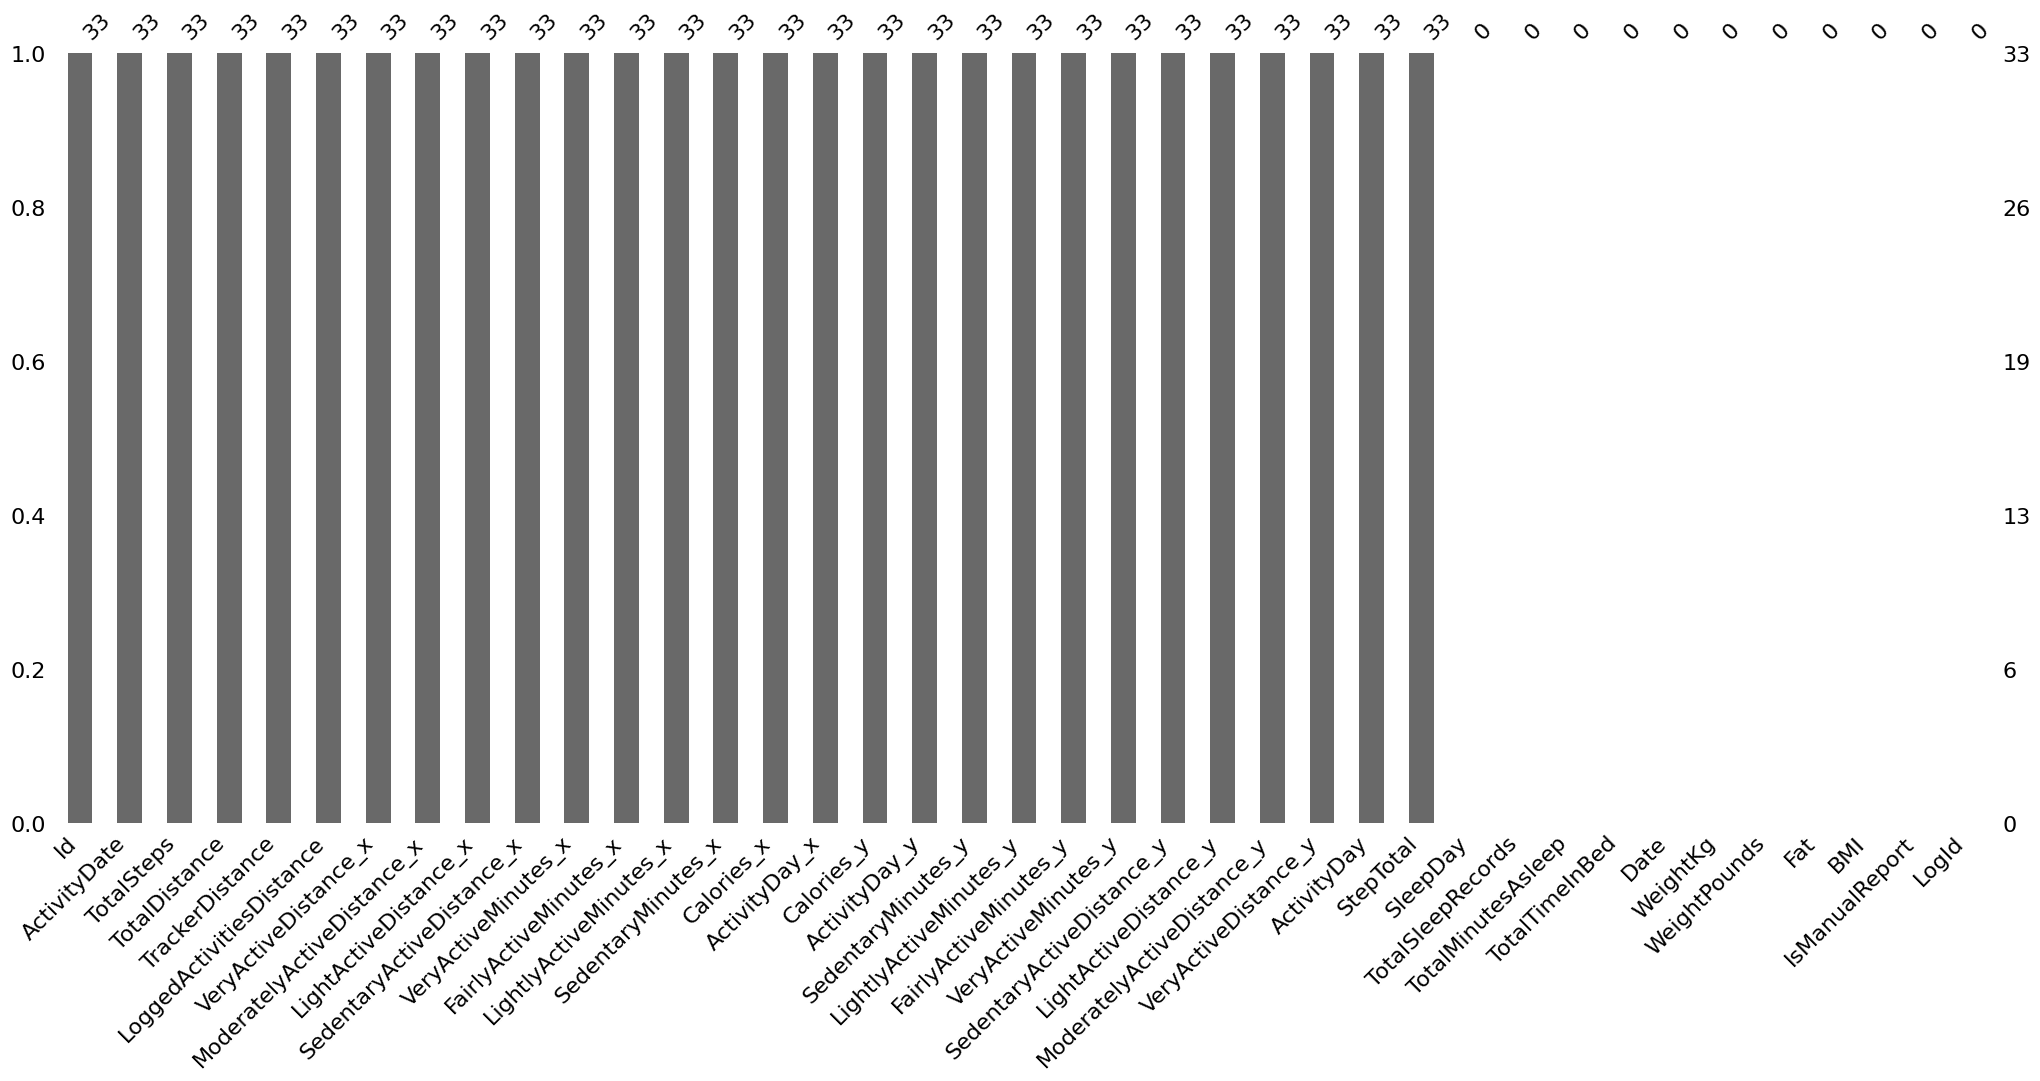

In [21]:
# Visualizing the missing values
ms.bar(md)
plt.show()

### What did you know about your dataset?

The following things which are about the datset:

1. There are 1004 rows and 6 duplicate rows.
2. There are 39 columns.

## ***2. Understanding Your Variables***

In [22]:
# Dataset Columns
md.columns

Index(['Id', 'ActivityDate', 'TotalSteps', 'TotalDistance', 'TrackerDistance',
       'LoggedActivitiesDistance', 'VeryActiveDistance_x',
       'ModeratelyActiveDistance_x', 'LightActiveDistance_x',
       'SedentaryActiveDistance_x', 'VeryActiveMinutes_x',
       'FairlyActiveMinutes_x', 'LightlyActiveMinutes_x', 'SedentaryMinutes_x',
       'Calories_x', 'ActivityDay_x', 'Calories_y', 'ActivityDay_y',
       'SedentaryMinutes_y', 'LightlyActiveMinutes_y', 'FairlyActiveMinutes_y',
       'VeryActiveMinutes_y', 'SedentaryActiveDistance_y',
       'LightActiveDistance_y', 'ModeratelyActiveDistance_y',
       'VeryActiveDistance_y', 'ActivityDay', 'StepTotal', 'SleepDay',
       'TotalSleepRecords', 'TotalMinutesAsleep', 'TotalTimeInBed', 'Date',
       'WeightKg', 'WeightPounds', 'Fat', 'BMI', 'IsManualReport', 'LogId'],
      dtype='object')

In [24]:
# Dataset Describe
md.describe

<bound method NDFrame.describe of               Id ActivityDate  TotalSteps  TotalDistance  TrackerDistance  \
0     1503960366    4/12/2016     13162.0           8.50             8.50   
58    1624580081    4/12/2016      8163.0           5.31             5.31   
89    1644430081    4/12/2016     10694.0           7.77             7.77   
123   1844505072    4/12/2016      6697.0           4.43             4.43   
157   1927972279    4/12/2016       678.0           0.47             0.47   
194   2022484408    4/12/2016     11875.0           8.34             8.34   
225   2026352035    4/12/2016      4414.0           2.74             2.74   
284   2320127002    4/12/2016     10725.0           7.49             7.49   
316   2347167796    4/12/2016     10113.0           6.83             6.83   
349   2873212765    4/12/2016      8796.0           5.91             5.91   
382   3372868164    4/12/2016      4747.0           3.24             3.24   
402   3977333714    4/12/2016      8856.0 

Answer Here

### Check Unique Values for each variable.

In [23]:
# Check Unique Values for each variable.
for x in md.columns:
    print(f"{x} - {md[x].nunique()}")

Id - 33
ActivityDate - 1
TotalSteps - 32
TotalDistance - 32
TrackerDistance - 32
LoggedActivitiesDistance - 3
VeryActiveDistance_x - 19
ModeratelyActiveDistance_x - 19
LightActiveDistance_x - 27
SedentaryActiveDistance_x - 2
VeryActiveMinutes_x - 18
FairlyActiveMinutes_x - 13
LightlyActiveMinutes_x - 29
SedentaryMinutes_x - 29
Calories_x - 32
ActivityDay_x - 1
Calories_y - 32
ActivityDay_y - 1
SedentaryMinutes_y - 29
LightlyActiveMinutes_y - 29
FairlyActiveMinutes_y - 13
VeryActiveMinutes_y - 18
SedentaryActiveDistance_y - 2
LightActiveDistance_y - 27
ModeratelyActiveDistance_y - 19
VeryActiveDistance_y - 19
ActivityDay - 1
StepTotal - 32
SleepDay - 0
TotalSleepRecords - 0
TotalMinutesAsleep - 0
TotalTimeInBed - 0
Date - 0
WeightKg - 0
WeightPounds - 0
Fat - 0
BMI - 0
IsManualReport - 0
LogId - 0


## 3. ***Data Wrangling***

### Data Wrangling Code

In [25]:
# Write your code to make your dataset analysis ready.
md.isnull().sum()

Id                             0
ActivityDate                   0
TotalSteps                     0
TotalDistance                  0
TrackerDistance                0
LoggedActivitiesDistance       0
VeryActiveDistance_x           0
ModeratelyActiveDistance_x     0
LightActiveDistance_x          0
SedentaryActiveDistance_x      0
VeryActiveMinutes_x            0
FairlyActiveMinutes_x          0
LightlyActiveMinutes_x         0
SedentaryMinutes_x             0
Calories_x                     0
ActivityDay_x                  0
Calories_y                     0
ActivityDay_y                  0
SedentaryMinutes_y             0
LightlyActiveMinutes_y         0
FairlyActiveMinutes_y          0
VeryActiveMinutes_y            0
SedentaryActiveDistance_y      0
LightActiveDistance_y          0
ModeratelyActiveDistance_y     0
VeryActiveDistance_y           0
ActivityDay                    0
StepTotal                      0
SleepDay                      33
TotalSleepRecords             33
TotalMinut

In [26]:
md.fillna({'Sleepday': 0}, inplace=True)
md.fillna({'TotalSleepRecords': 0}, inplace=True)
md.fillna({'TotalMinutesAsleep': 0}, inplace=True)
md.fillna({'TotalTimeInBed': 0}, inplace=True)
md['Date'] = md['Date'].fillna('Missing')
md.fillna({'weightKg': 0}, inplace=True)
md.fillna({'weightPounds': 0}, inplace=True)
md.fillna({'Fat': 0}, inplace=True)
md.fillna({'BMI': 0}, inplace=True)
md.fillna({'IsManualReport': 'Missing'}, inplace=True)
md.fillna({'LogId': 0}, inplace=True)

In [27]:
md.isnull().sum()

Id                             0
ActivityDate                   0
TotalSteps                     0
TotalDistance                  0
TrackerDistance                0
LoggedActivitiesDistance       0
VeryActiveDistance_x           0
ModeratelyActiveDistance_x     0
LightActiveDistance_x          0
SedentaryActiveDistance_x      0
VeryActiveMinutes_x            0
FairlyActiveMinutes_x          0
LightlyActiveMinutes_x         0
SedentaryMinutes_x             0
Calories_x                     0
ActivityDay_x                  0
Calories_y                     0
ActivityDay_y                  0
SedentaryMinutes_y             0
LightlyActiveMinutes_y         0
FairlyActiveMinutes_y          0
VeryActiveMinutes_y            0
SedentaryActiveDistance_y      0
LightActiveDistance_y          0
ModeratelyActiveDistance_y     0
VeryActiveDistance_y           0
ActivityDay                    0
StepTotal                      0
SleepDay                      33
TotalSleepRecords              0
TotalMinut

### What all manipulations have you done and insights you found?

1.Missing data has been handled, making the dataset easier to analyze.
However, replacing values like BMI, weight, and sleep time with 0 may create unrealistic data.
2."Missing" is more appropriate for categorical/text fields.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

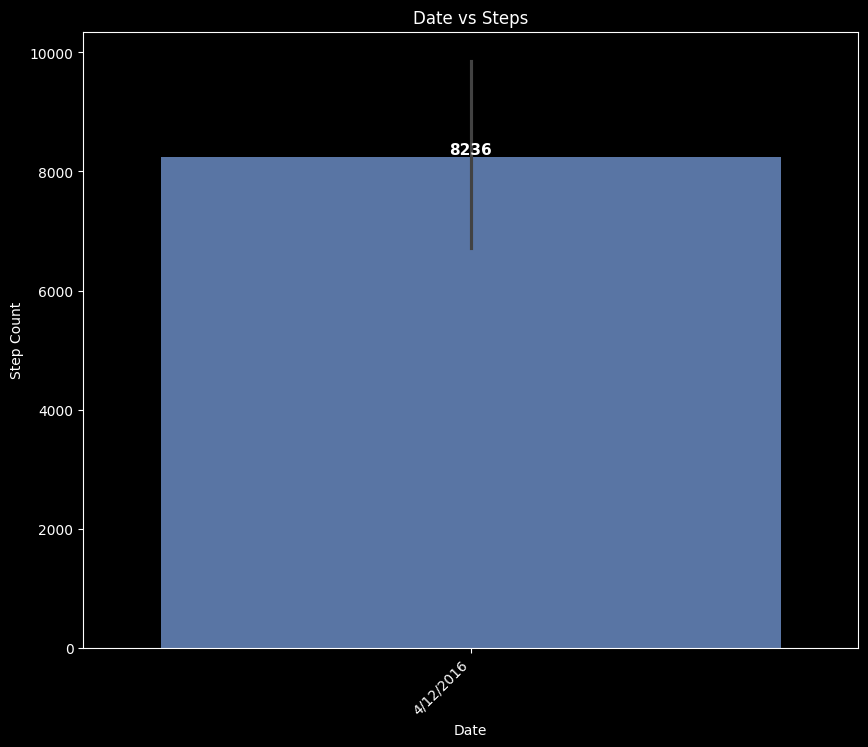

In [28]:
# Chart - 1 Visualization code
plt.style.use('dark_background')

# Create a bar plot
plt.figure(figsize=(10, 8))  # Adjust figure size
ax = sns.barplot(data=md, x='ActivityDate', y='TotalSteps',
                 hue='ActivityDate', palette='deep', legend=False)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.xlabel("Date")
plt.ylabel("Step Count")
plt.title("Date vs Steps")

for p in ax.patches:
    count = int(p.get_height())
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    
    ax.annotate(
        str(count),
        (x, y),
        ha='center',
        va='bottom',
        fontsize=11,
        color='white',
        fontweight='bold'
    )

# Show the plot
plt.show()

##### 1. Why did you pick the specific chart?

The above bar plot gives clear count in vertical visual.

##### 2. What is/are the insight(s) found from the chart?

The Count total steps for the activity date is 8236.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The people are consistent with working out specially walking and reaching their step goals.

#### Chart - 2

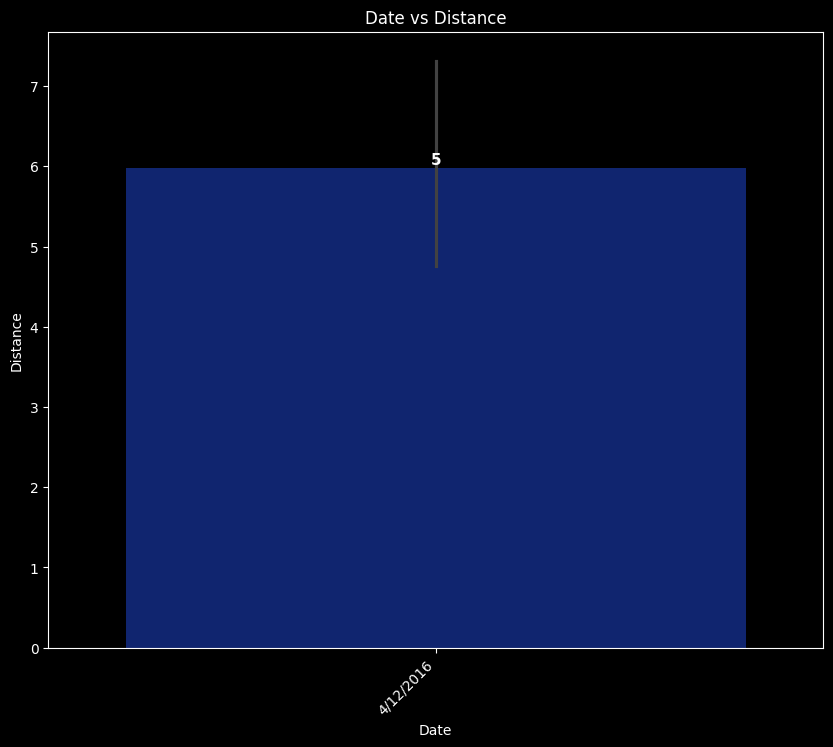

In [29]:

# Chart - 2 Visualization code
plt.style.use('dark_background')

# Create a bar plot
plt.figure(figsize=(10, 8))  # Adjust figure size
ax = sns.barplot(data=md, x='ActivityDate', y='TotalDistance',
                 hue='ActivityDate', palette='dark', legend=False)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.xlabel('Date')
plt.ylabel('Distance')
plt.title('Date vs Distance')

for p in ax.patches:
    count = int(p.get_height())
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(
        str(count),
        (x, y),
        ha='center',
        va='bottom',
        fontsize=11,
        color='white',
        fontweight='bold'
    )

# Show the plot
plt.show()

##### 1. Why did you pick the specific chart?

The bar plot clearly compares the total distance covered on different activity dates.



##### 2. What is/are the insight(s) found from the chart?

The chart shows that the distance covered varies across different dates, indicating different levels of physical activity.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It shows that people are actively walking and maintaining physical activity. This can support fitness-related products and services. Low-distance days may indicate areas where users need more motivation to stay active.

#### Chart - 3

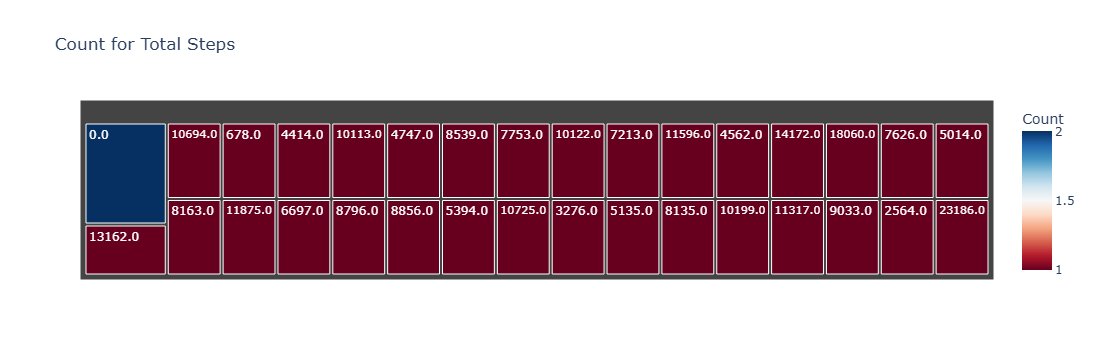

In [30]:

# Chart - 3 visualization code
plt.style.use('dark_background')

md.columns = md.columns.str.strip()

# Count occurrences of each start station
step_count = md["TotalSteps"].value_counts().reset_index()
step_count.columns = ["TotalSteps", "Count"]

# Create the treemap
fig = px.treemap(
    step_count,
    path=['TotalSteps'],
    values='Count',
    title="Count for Total Steps",
    color='Count',
    color_continuous_scale="RdBu"
)

# Show the plot
fig.show()

##### 1. Why did you pick the specific chart?

The treemap clearly shows the frequency of different total step counts using size and color.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that some step counts occur more frequently, indicating common daily activity levels among users.

 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It helps identify users’ common activity levels, which can support personalized fitness goals and motivation programs. Lower activity levels may indicate a need for more engagement.

#### Chart - 4

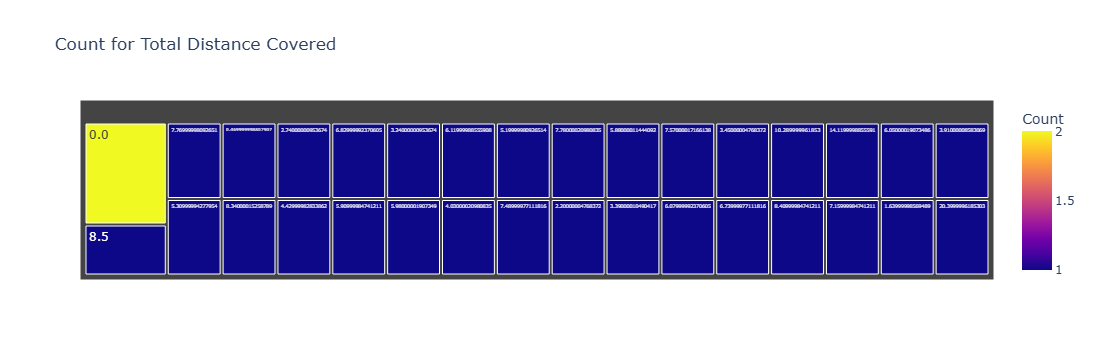

In [31]:
# Chart - 4 visualization code
plt.style.use('dark_background')

md.columns = md.columns.str.strip()

# Count occurrences of each Total Distance
distance_count = md["TotalDistance"].value_counts().reset_index()
distance_count.columns = ["TotalDistance", "Count"]

# Create the treemap
fig = px.treemap(
    distance_count,
    path=['TotalDistance'],
    values='Count',
    title="Count for Total Distance Covered",
    color='Count',
    color_discrete_map={
        '?': 'lightgrey',
        'Lunch': 'gold',
        'Dinner': 'darkblue'
    }
)

# Show the plot
fig.show()


##### 1. Why did you pick the specific chart?

The treemap clearly shows the frequency of different total distances covered by users.



##### 2. What is/are the insight(s) found from the chart?

The chart shows that some distance ranges are more common, indicating users have different levels of daily physical activity.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It helps understand users’ activity patterns and can support personalized fitness goals and activity recommendations. Lower activity levels may indicate a need for more motivation.

#### Chart - 5

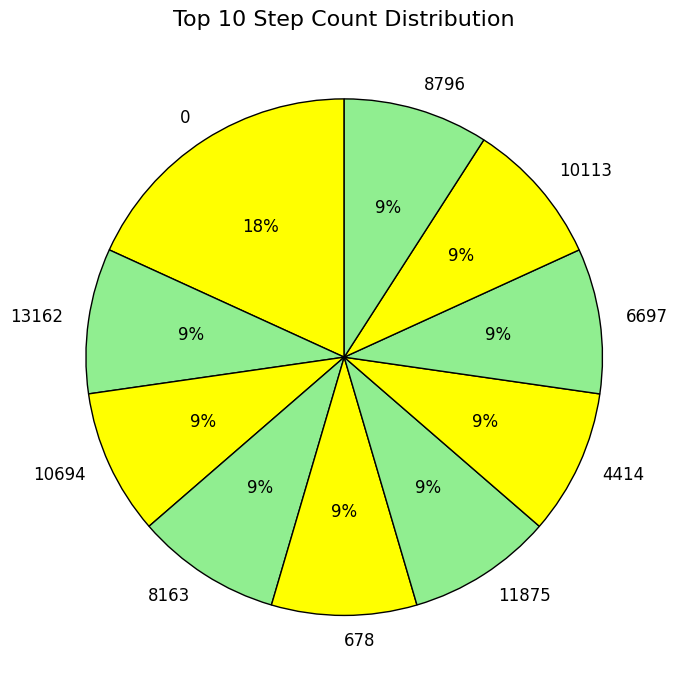

In [32]:

# Chart - 5 visualization code
plt.style.use('default')

md.columns = md.columns.str.strip()

co = md['StepTotal'].value_counts().head(10)
co.index = co.index.astype(int)  # <- make the year labels integers

plt.figure(figsize=(15, 7))

plt.pie(
    co.values,
    labels=[str(year) for year in co.index],  # <- use labels explicitly
    autopct=lambda p: '{:.0f}%'.format(p),  # whole numbers, no decimal
    colors=['yellow', 'lightgreen'],
    startangle=90,
    wedgeprops={'edgecolor': 'black'},
    textprops={'fontsize': 12, 'color': 'black'}
)

plt.title('Top 10 Step Count Distribution', fontsize=16)
plt.ylabel('')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The pie chart clearly shows the distribution of the top 10 step counts and their percentage contribution.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that some step counts occur more frequently than others, with the highest step counts making up a larger share.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It helps identify common step-count patterns, which can be used to set realistic fitness goals and encourage users to increase their activity.

#### Chart - 6

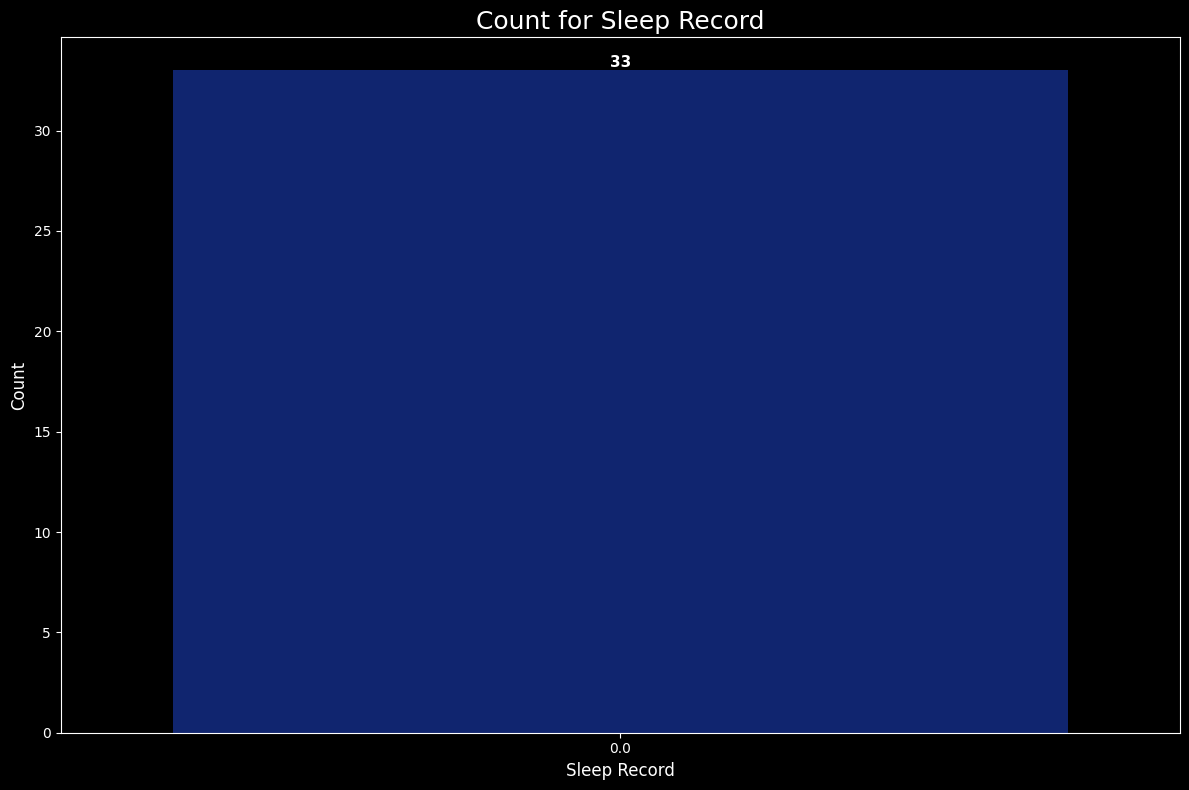

In [33]:

# Chart - 6 visualization code
plt.style.use('dark_background')

md.columns = md.columns.str.strip()

plt.figure(figsize=(12, 8))

ax = sns.countplot(
    x='TotalSleepRecords',
    data=md,
    hue='TotalSleepRecords',
    palette='dark',
    legend=False
)

plt.title('Count for Sleep Record', fontsize=18)
plt.xlabel('Sleep Record', fontsize=12)
plt.ylabel('Count', fontsize=12)

for p in ax.patches:
    count = int(p.get_height())
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()

    ax.annotate(
        str(count),
        (x, y),
        ha='center',
        va='bottom',
        fontsize=11,
        color='white',
        fontweight='bold'
    )

plt.grid(False)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The count plot clearly shows the number of sleep records and how frequently each value occurs.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that users have different numbers of sleep records, with some record counts occurring more frequently than others.

 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It helps understand users’ sleep-tracking patterns, which can support better sleep-monitoring features and personalized health recommendations.

#### Chart - 7

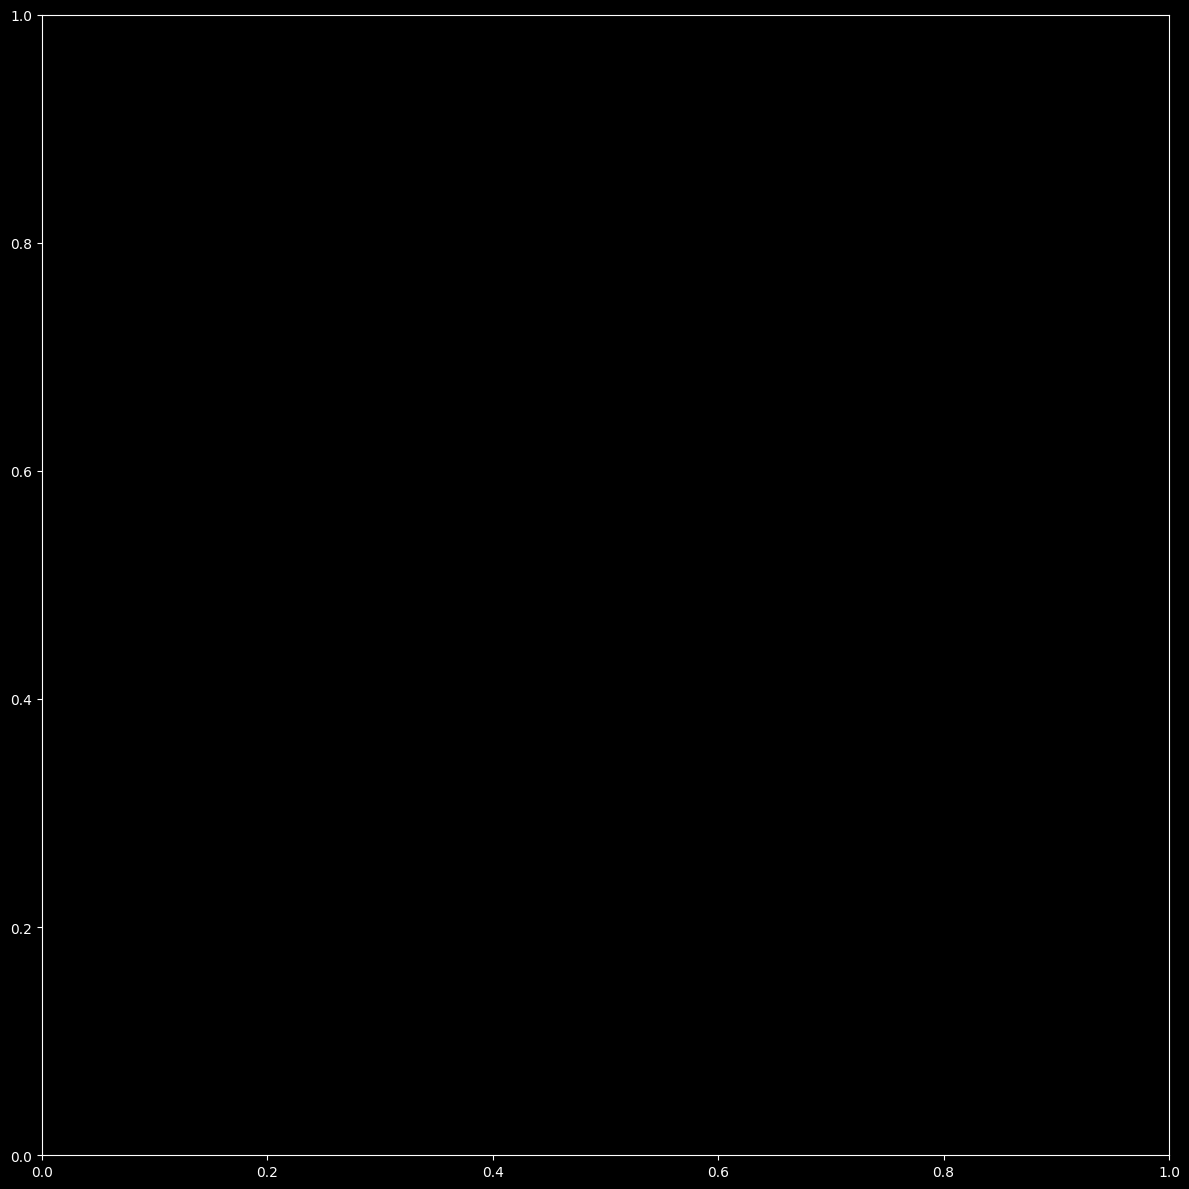

In [38]:
# Chart - 7 visualization code
plt.style.use('dark_background')

numerical_features = [
    'VeryActiveMinutes_x',
    'FairlyActiveMinutes_x',
    'LightlyActiveMinutes_x',
    'VeryActiveDistance',
    'TotalSteps',
    'TotalDistance',
    'TrackerDistance',
    'SedentaryMinutes_x',
    'SedentaryMinutes'
]

# Keep only columns that exist in df
numerical_features = [column for column in numerical_features if column in df.columns]

plt.figure(figsize=(12, 12))

for i, column in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[column], bins=20, color='lightgreen')
    plt.title(f'Distribution of {column}')
    plt.xlabel('Count')
    plt.ylabel('Count')

plt.grid(False)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The histogram is useful for showing the distribution and frequency of different activity levels such as steps, distance, and active minutes.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that activity levels vary among users, with most observations concentrated around certain ranges.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It helps identify common activity patterns and can support personalized fitness plans. Users with lower activity levels can be targeted with motivation and engagement strategies.

#### Chart - 8

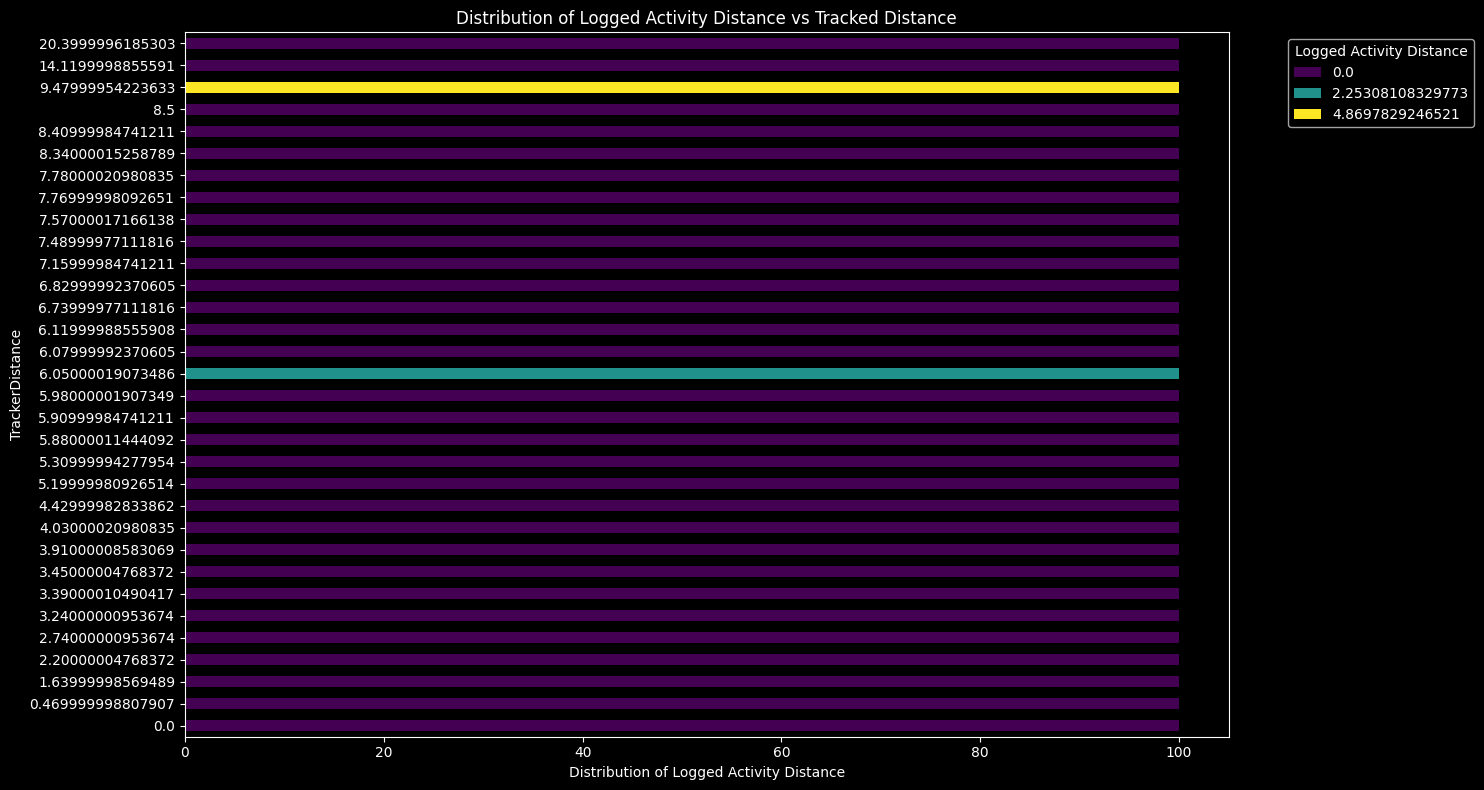

In [41]:
# Chart - 8 visualization code

data = md.groupby(
    ['TrackerDistance', 'LoggedActivitiesDistance']
).size().unstack(fill_value=0)

# Normalize the data (percentage distribution)
data_1 = data.div(data.sum(axis=1), axis=0) * 100

# Plot stacked bar chart
fig, ax = plt.subplots(figsize=(15, 8))
data_1.plot(kind='barh', stacked=True, colormap='viridis', ax=ax)

# Labels and title
plt.xlabel('Distribution of Logged Activity Distance')
plt.ylabel('TrackerDistance')
plt.title('Distribution of Logged Activity Distance vs Tracked Distance')

plt.legend(
    title='Logged Activity Distance',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The stacked bar chart clearly compares tracked distance with logged activity distance and shows their percentage distribution.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that most tracked distances have different proportions of logged activity, indicating variations in how users record their activities.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It can help improve activity tracking and logging features. Differences between tracked and logged activities may also indicate opportunities to encourage users to record their activities more consistently.

#### Chart - 9

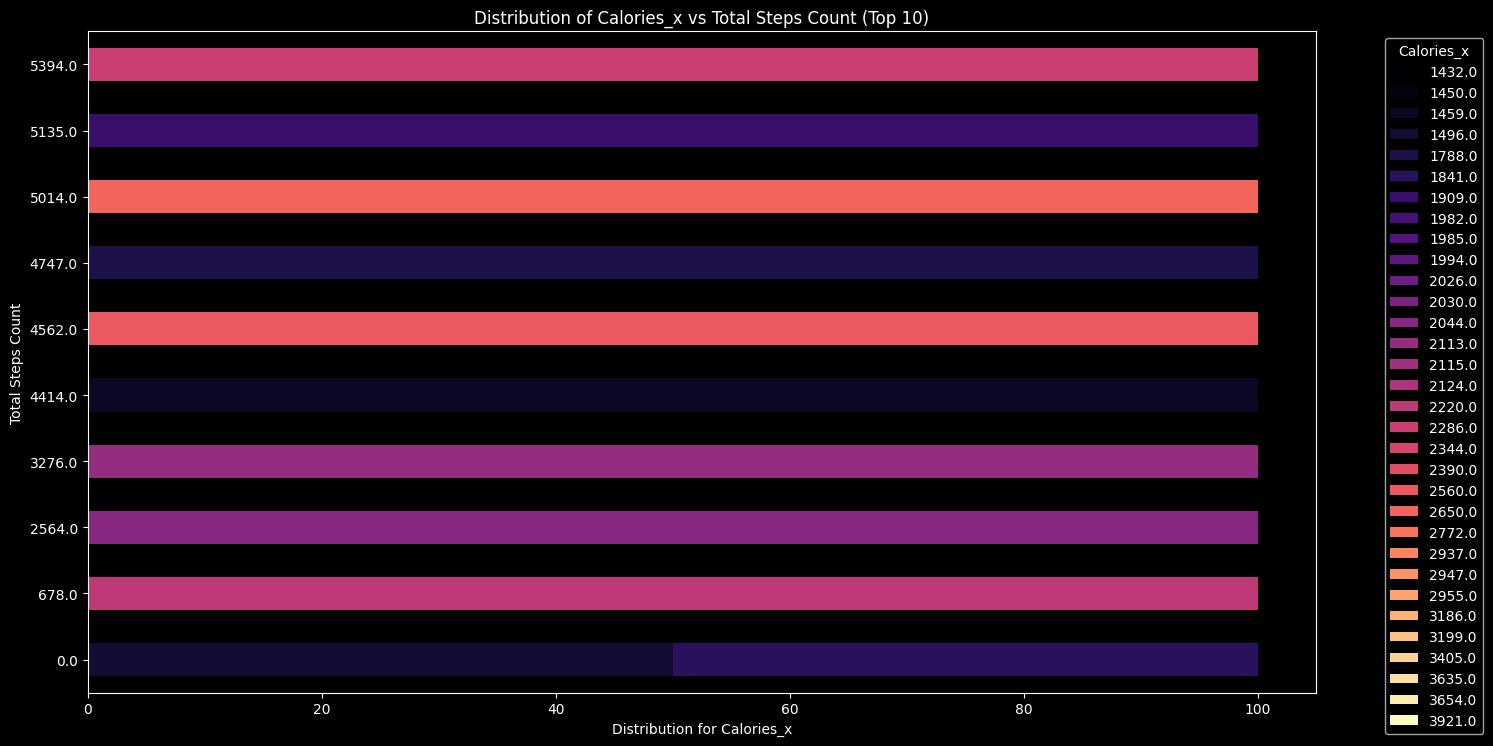

In [42]:
# Chart - 9 visualization code
plt.style.use('dark_background')

data_cx = md.groupby(["TotalSteps", "Calories_x"]).size().unstack(fill_value=0)

# Normalize the data (percentage distribution)
data_cx1 = data_cx.div(data_cx.sum(axis=1), axis=0) * 100

# Select top 10 stations by total trip count
TotalSteps1 = data_cx1.sum(axis=1).sort_values(ascending=False).head(10).index
TotalSteps_cx = data_cx1.loc[TotalSteps1]

# Plot stacked bar chart
fig, ax = plt.subplots(figsize=(15, 8))  # Adjusted figure size
TotalSteps_cx.plot(kind="barh", stacked=True, colormap="magma", ax=ax)

# Labels and title
plt.xlabel("Distribution for Calories_x")
plt.ylabel("Total Steps Count")
plt.title("Distribution of Calories_x vs Total Steps Count (Top 10)")
plt.legend(title="Calories_x", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The stacked bar chart clearly shows the relationship between total steps and calories burned for the top 10 step counts.

##### 2. What is/are the insight(s) found from the chart?

The chart indicates that calorie expenditure varies with different step counts, showing that higher activity levels are generally associated with more calories burned

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. This insight can help provide personalized calorie-burning and step goals, encouraging users to increase their physical activity and engagement.

#### Chart - 10

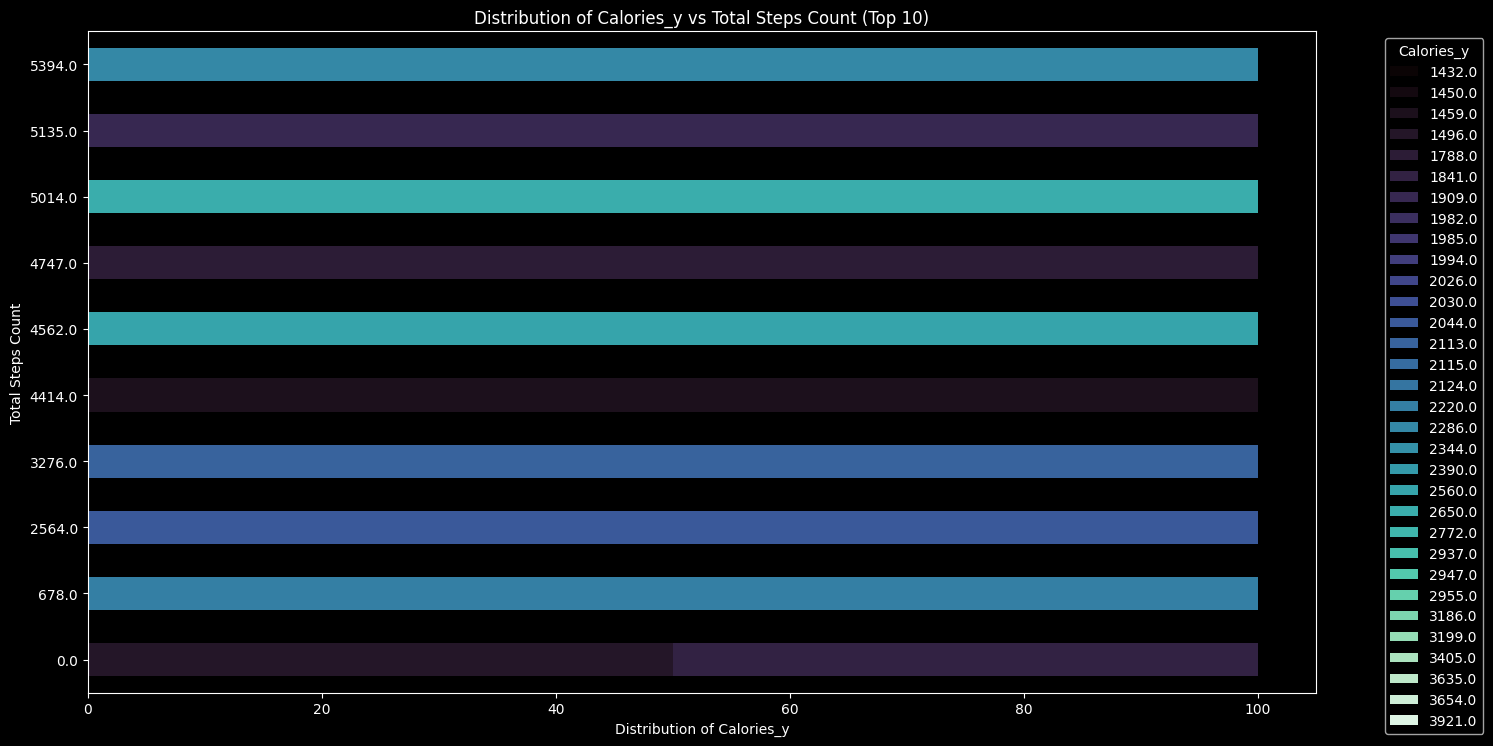

In [43]:
# Chart - 10 visualization code

plt.style.use('dark_background')

data_cy = md.groupby(['TotalSteps', 'Calories_y']).size().unstack(fill_value=0)

# Normalize the data (percentage distribution)
data_cy = data_cy.div(data_cy.sum(axis=1), axis=0) * 100

# Select top 20 stations by total trip count
TotalSteps_cy = data_cy.sum(axis=1).sort_values(ascending=False).head(10).index
TotalSteps_cy = data_cy.loc[TotalSteps_cy]

# Plot stacked bar chart
fig, ax = plt.subplots(figsize=(15, 8))  # Adjusted figure size
TotalSteps_cy.plot(
    kind='barh',
    stacked=True,
    colormap='mako',
    ax=ax
)

# Labels and title
plt.xlabel('Distribution of Calories_y')
plt.ylabel('Total Steps Count')
plt.title('Distribution of Calories_y vs Total Steps Count (Top 10)')

plt.legend(
    title='Calories_y',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The stacked bar chart clearly compares total steps with calories burned and shows their distribution for the top 10 step counts.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that calorie expenditure varies across different step counts, indicating differences in users' activity levels.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It can help create personalized step and calorie goals, encouraging users to stay active and improve their fitness.

#### Chart - 11

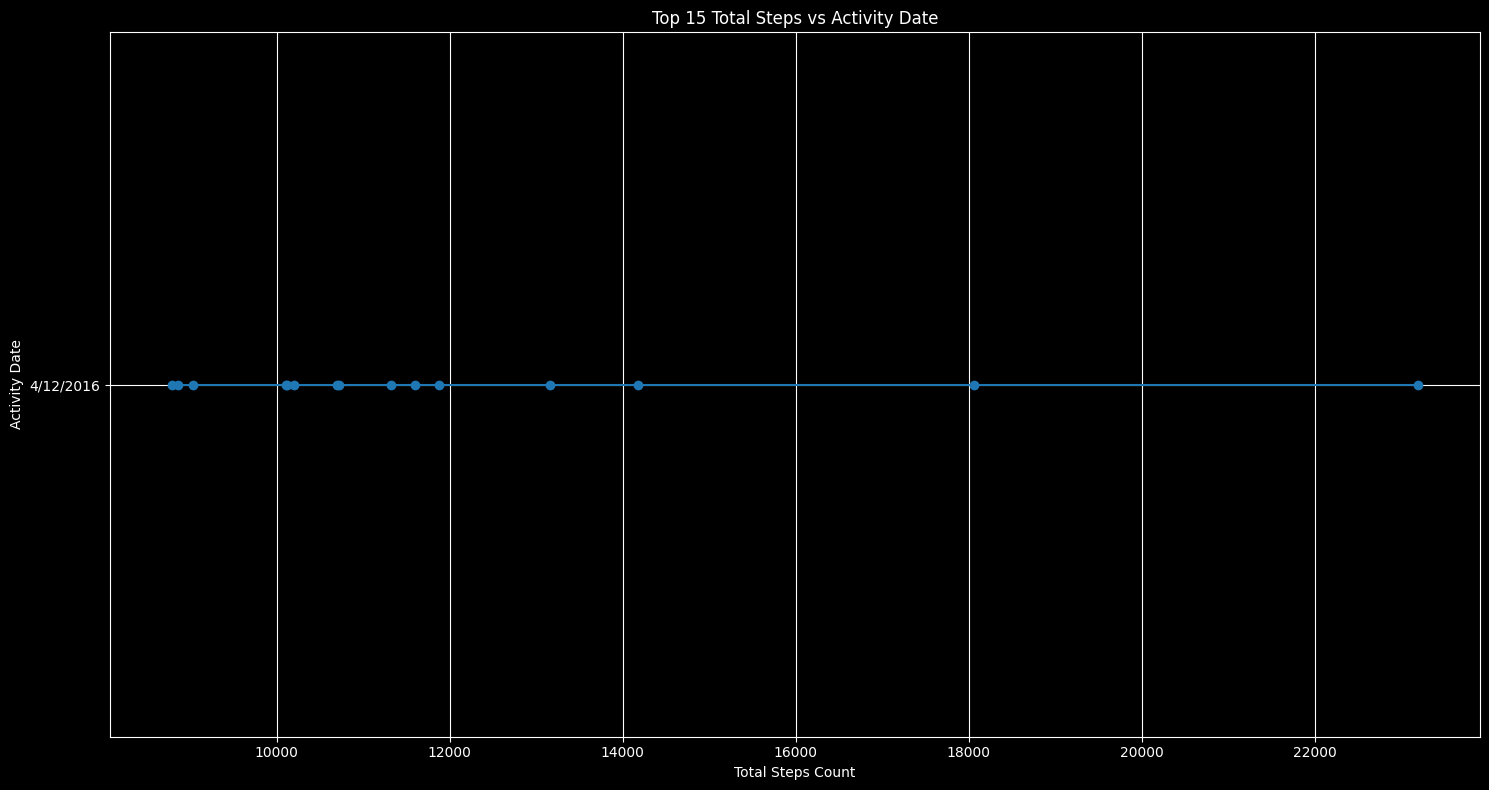

In [44]:
# Chart - 11 visualization code

plt.style.use('dark_background')

# Remove any leading or trailing spaces from column names
md.columns = md.columns.str.strip()

# Sort by date_added and select the top 15
top_date_added = md[['TotalSteps', 'ActivityDate']].sort_values(
    by='TotalSteps',
    ascending=False
).head(15)

# Plot the results
plt.figure(figsize=(15, 8))

plt.plot(
    top_date_added['TotalSteps'],
    top_date_added['ActivityDate'],
    marker='o',
    color='tab:blue',
    linestyle='-'
)

plt.xlabel('Total Steps Count')
plt.ylabel('Activity Date')
plt.title('Top 15 Total Steps vs Activity Date')
plt.grid(True)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The line chart clearly shows the top 15 total step counts across different activity dates.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that step counts vary across the selected dates, with some dates having significantly higher activity levels.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Identifying highly active dates can help businesses understand user activity patterns and create targeted challenges or rewards to encourage consistent exercise.

#### Chart - 12

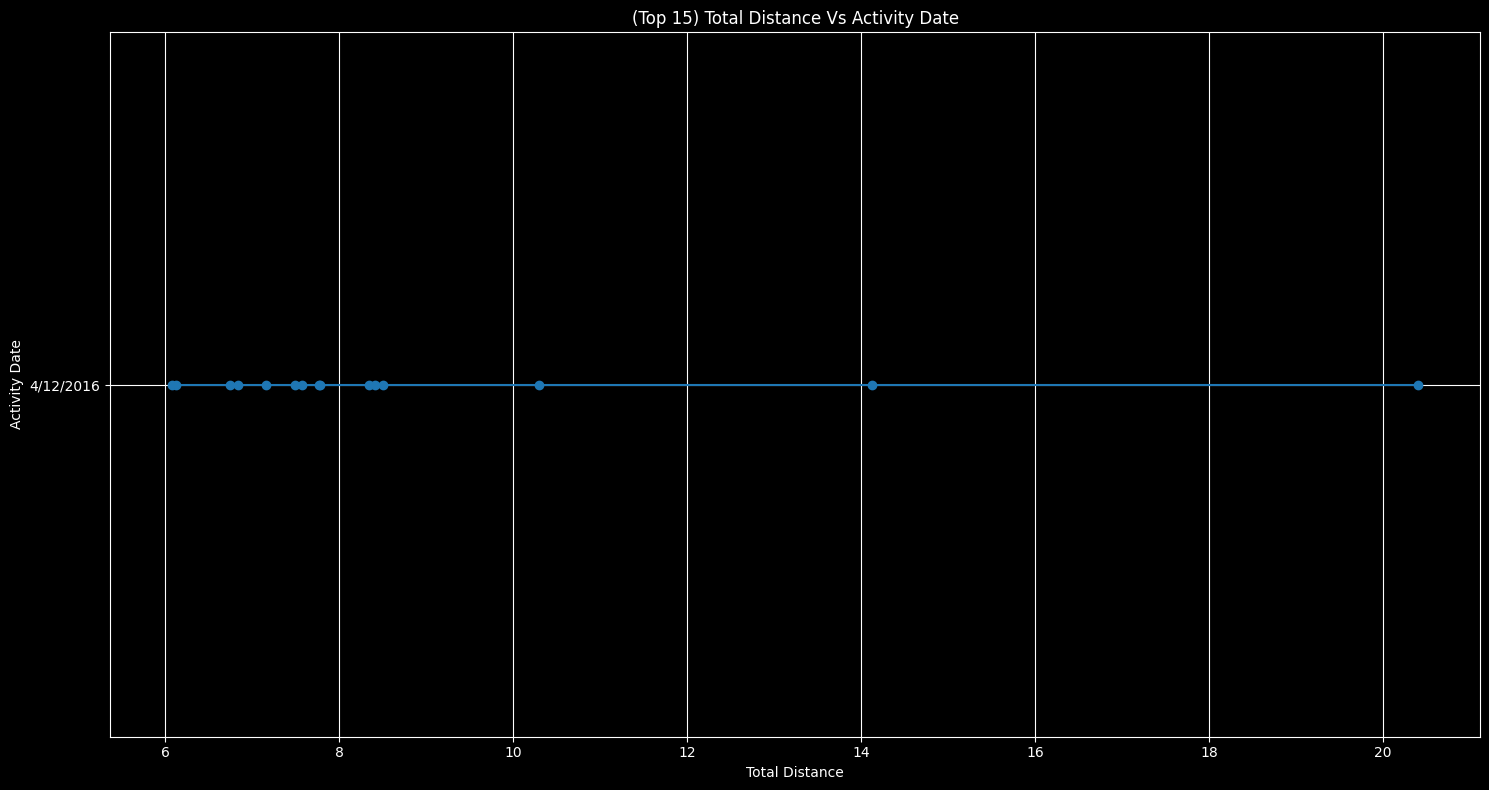

In [45]:
# Chart - 12 visualization code

plt.style.use('dark_background')

# Remove any leading or trailing spaces from column names
md.columns = md.columns.str.strip()

# Sort by date and release year, then select the top 15
top_distance = md[['TotalDistance', 'ActivityDate']].sort_values(
    by='TotalDistance',
    ascending=False
).head(15)

# Plot the results
plt.figure(figsize=(15, 8))

plt.plot(
    top_distance['TotalDistance'],
    top_distance['ActivityDate'],
    marker='o',
    color='tab:blue',
    linestyle='-'
)

plt.xlabel("Total Distance")
plt.ylabel("Activity Date")
plt.title("(Top 15) Total Distance Vs Activity Date")
plt.grid(True)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The line chart clearly shows the top 15 total step counts across different activity dates.



##### 2. What is/are the insight(s) found from the chart?

The chart shows that step counts vary across the selected dates, with some dates having significantly higher activity levels.

3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Identifying highly active dates can help businesses understand user activity patterns and create targeted challenges or rewards to encourage consistent exercise.

#### Chart - 13

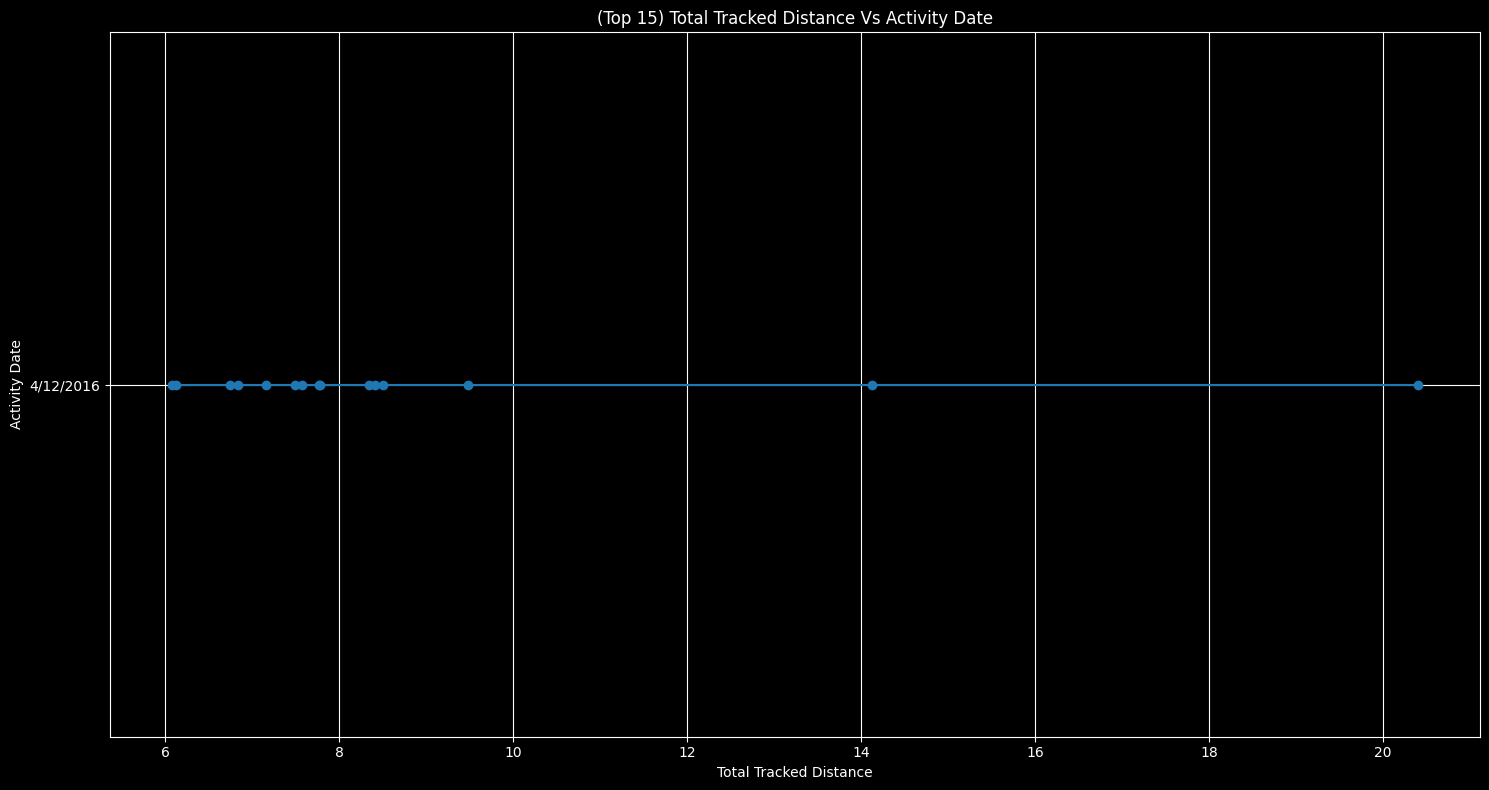

In [46]:
# Chart - 13 visualization code

plt.style.use('dark_background')

# Remove any leading or trailing spaces from column names
md.columns = md.columns.str.strip()

# Sort by date_added and release_year, then select the top 15
top_tracked = md[['TrackerDistance', 'ActivityDate']].sort_values(
    by='TrackerDistance',
    ascending=False
).head(15)

# Plot the results
plt.figure(figsize=(15, 8))

plt.plot(
    top_tracked['TrackerDistance'],
    top_tracked['ActivityDate'],
    marker='o',
    color='tab:blue',
    linestyle='-'
)

plt.xlabel('Total Tracked Distance')
plt.ylabel('Activity Date')
plt.title('(Top 15) Total Tracked Distance Vs Activity Date')
plt.grid(True)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Yes. Identifying highly active dates can help businesses understand user activity patterns and create targeted challenges or rewards to encourage consistent exercise.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that step counts vary across the selected dates, with some dates having significantly higher activity levels.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Identifying highly active dates can help businesses understand user activity patterns and create targeted challenges or rewards to encourage consistent exercise.

#### Chart - 14 - Correlation Heatmap

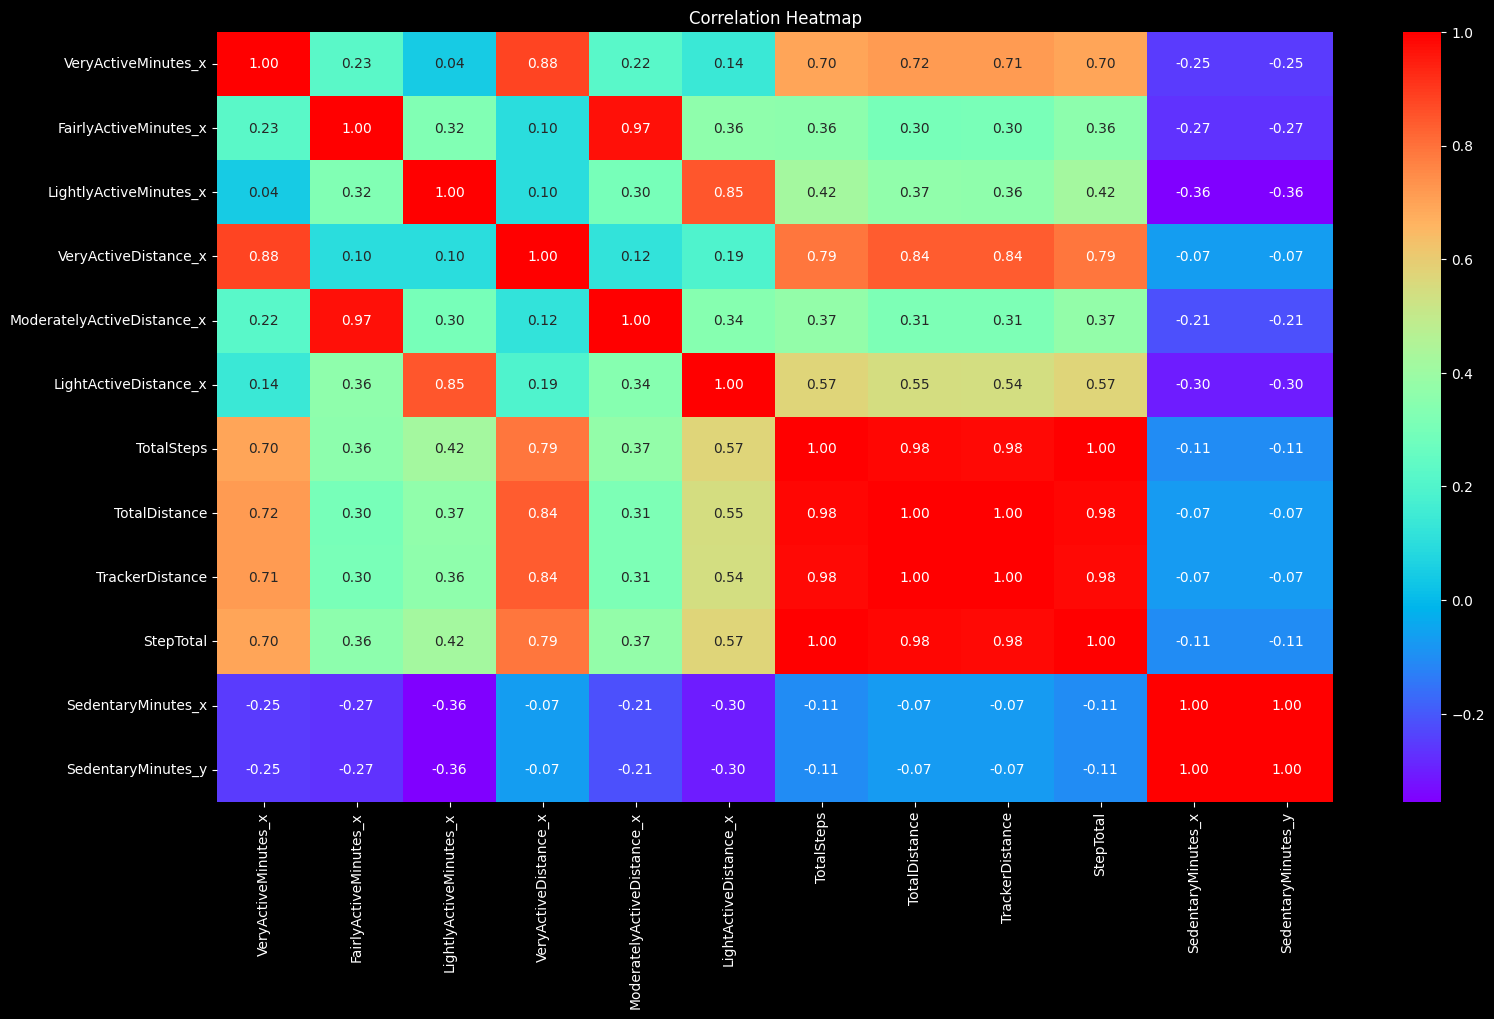

In [47]:
# Correlation Heatmap visualization code


columns_to_include = [
    'VeryActiveMinutes_x',
    'FairlyActiveMinutes_x',
    'LightlyActiveMinutes_x',
    'VeryActiveDistance_x',
    'ModeratelyActiveDistance_x',
    'LightActiveDistance_x',
    'TotalSteps',
    'TotalDistance',
    'TrackerDistance',
    'StepTotal',
    'SedentaryMinutes_x',
    'SedentaryMinutes_y'
]

# Filter the DataFrame using column names
md2 = md[columns_to_include]

# Compute the correlation matrix
md3 = md2.corr()

# Plot the heatmap
plt.figure(figsize=(18, 10))
sns.heatmap(md3, annot=True, cmap="rainbow", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

##### 1. Why did you pick the specific chart?

The correlation heatmap clearly shows the relationship between different physical activity variables using correlation values.

##### 2. What is/are the insight(s) found from the chart?

The heatmap helps identify strong positive and negative correlations. For example, steps and distance are expected to have a strong positive relationship, meaning more steps generally correspond to greater distance.

#### Chart - 15 - Pair Plot

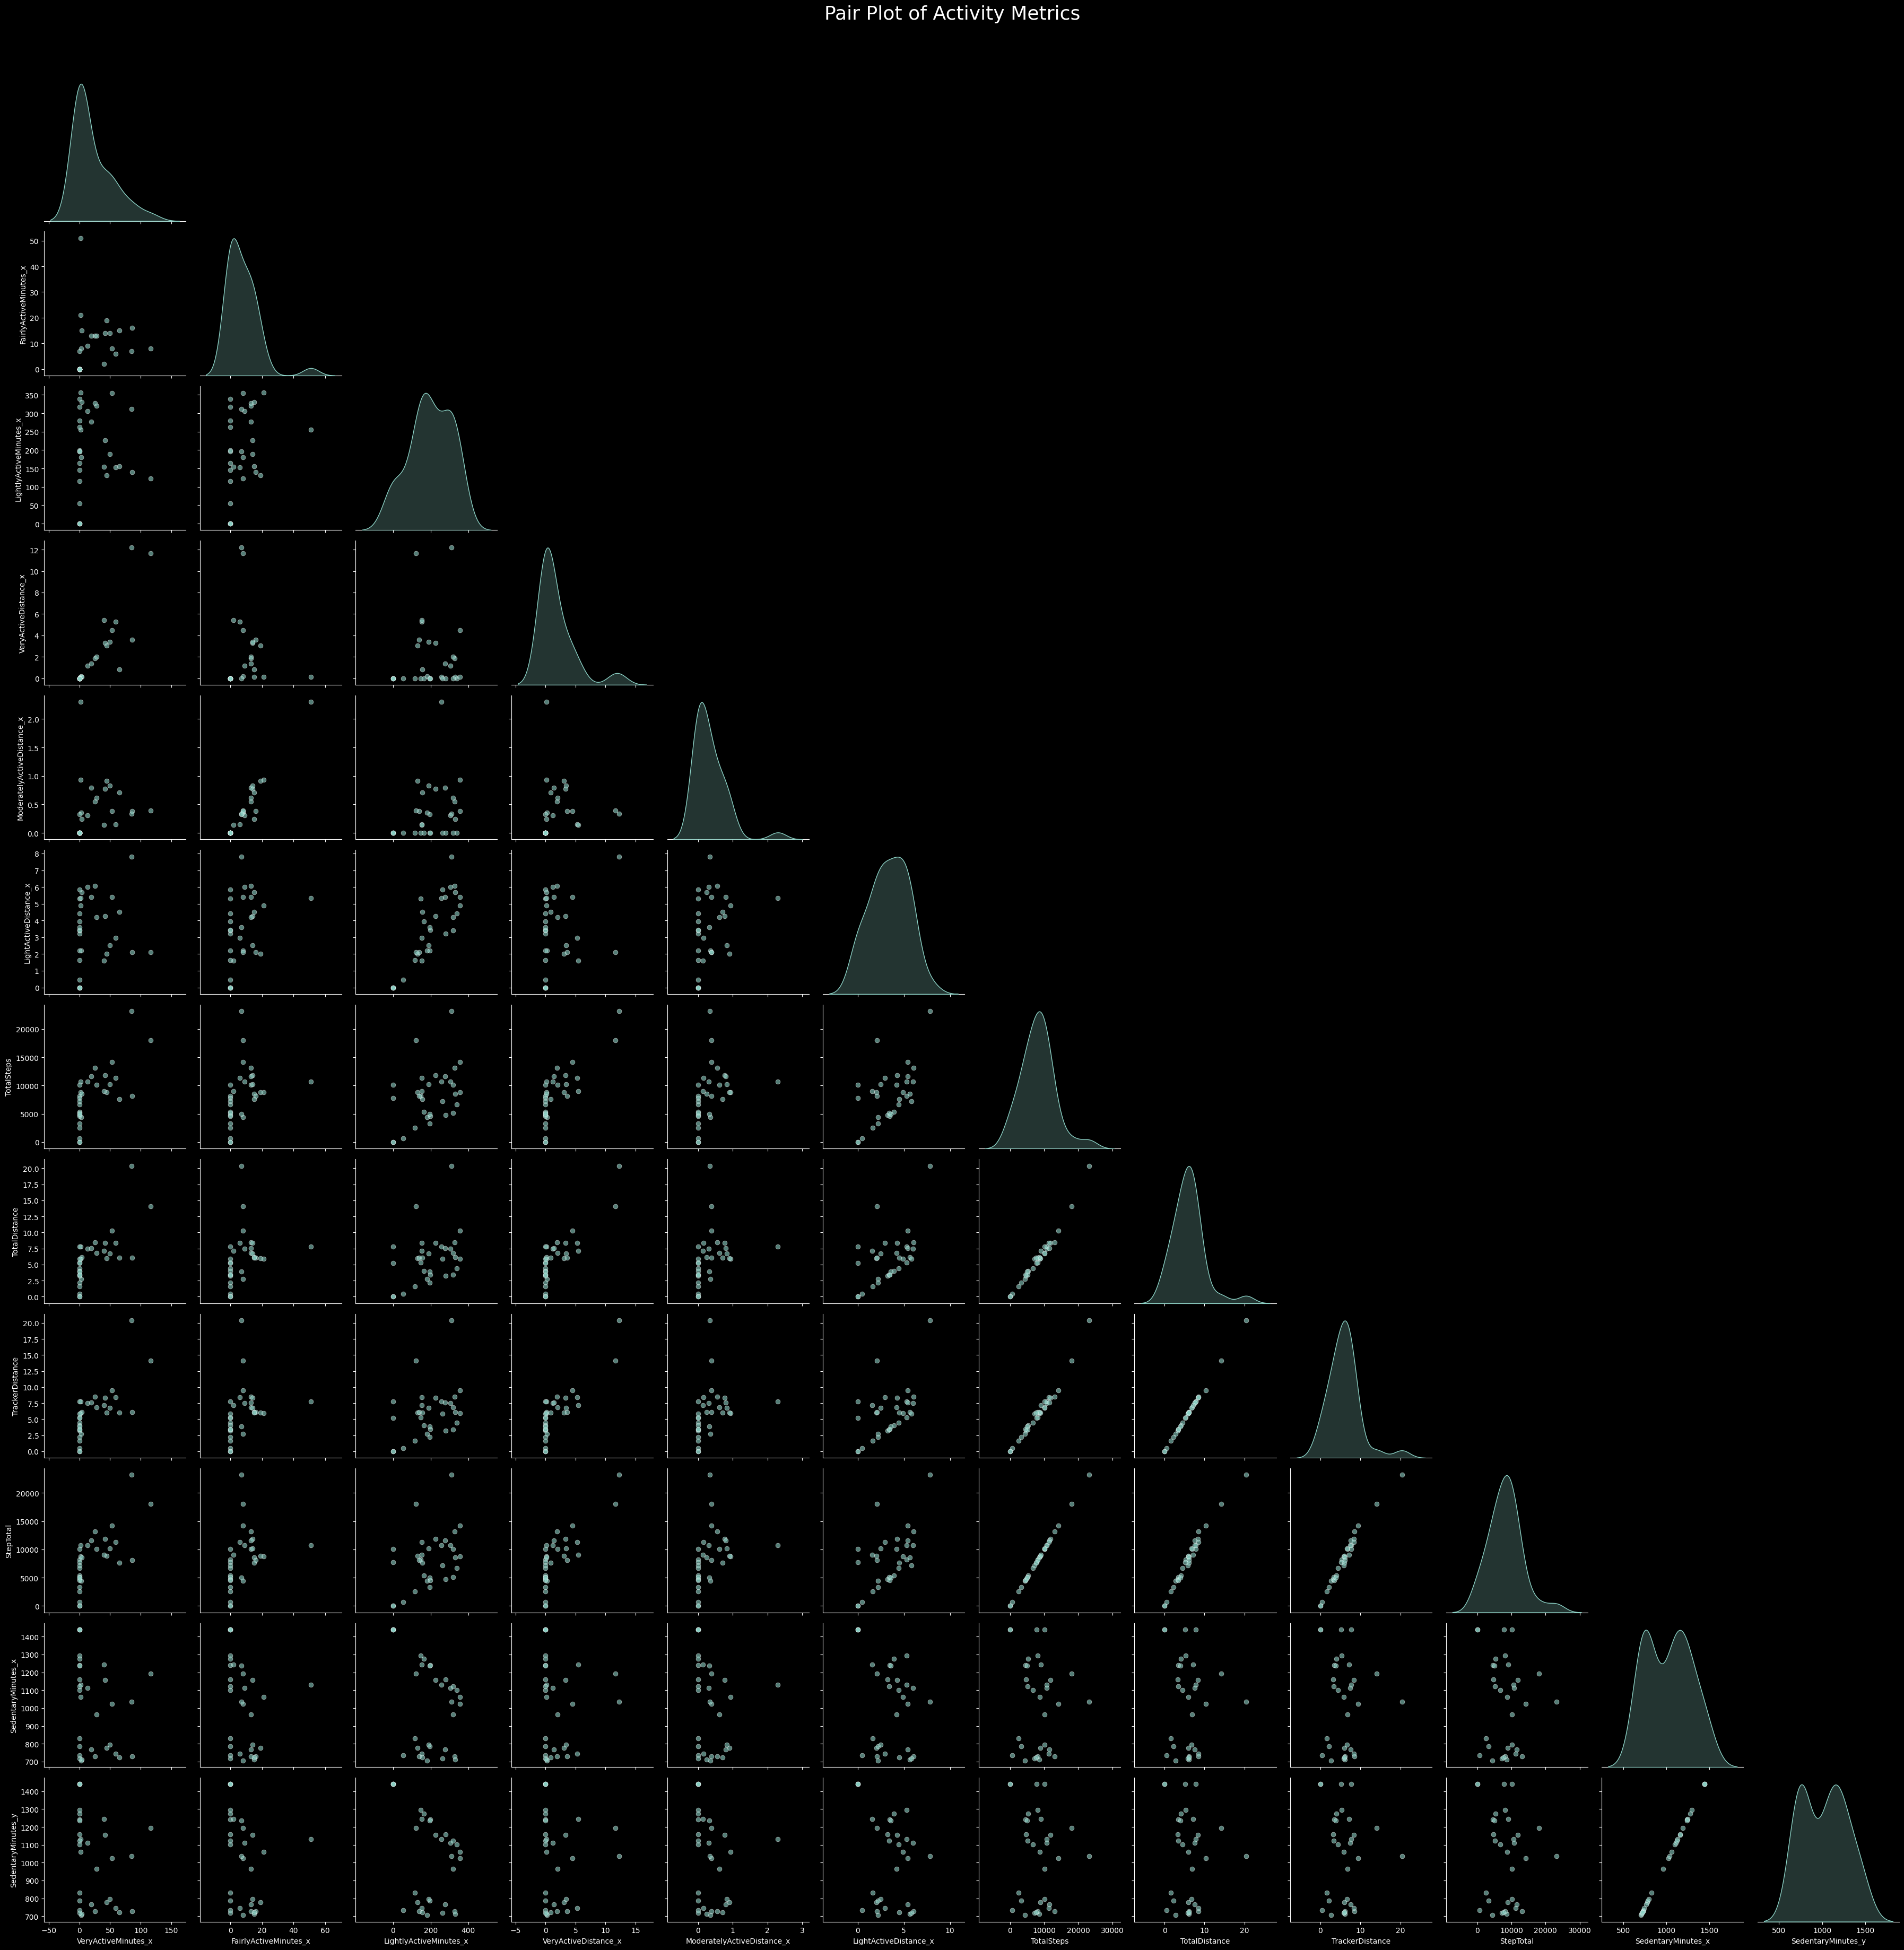

In [48]:
# Pair Plot visualization code


columns_to_include = [
    'VeryActiveMinutes_x',
    'FairlyActiveMinutes_x',
    'LightlyActiveMinutes_x',
    'VeryActiveDistance_x',
    'ModeratelyActiveDistance_x',
    'LightActiveDistance_x',
    'TotalSteps',
    'TotalDistance',
    'TrackerDistance',
    'StepTotal',
    'SedentaryMinutes_x',
    'SedentaryMinutes_y'
]

# Filter the DataFrame using selected columns
md2 = md[columns_to_include]

# Plot the pair plot with controlled figure size
# (approx 4 plots per row)
sns.pairplot(
    md2,
    corner=True,
    diag_kind='kde',
    plot_kws={'alpha': 0.6, 's': 40},
    height=3,       # Height of each subplot
    aspect=1        # Width = height × aspect ratio
)

plt.suptitle("Pair Plot of Activity Metrics", y=1.02, fontsize=26)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The pair plot helps visualize the relationships and distributions between multiple activity metrics at the same time.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that variables such as TotalSteps, TotalDistance, and TrackerDistance have a strong positive relationship, while activity levels vary across users.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

The following are the suggestions for the business to improve and achieve their targets and solve business problems.

1.Strava can encourage users to track and log their daily distance along with their steps. This will provide more accurate and complete activity records and help users monitor their monthly fitness progress effectively.

2.Strava can organize fitness campaigns, seminars, webinars, challenges, and reward programs to encourage more people to join and actively use the app. This can help users achieve their fitness goals while increasing user engagement and business growth.

3.Strava can introduce a reward system where users who achieve specific fitness targets receive offers or discounts on paid memberships or subscriptions. This can motivate users to stay active and healthy while encouraging them to upgrade to premium services, ultimately increasing the number of premium users and company revenue.

# **Conclusion**

The analysis shows that Strava can improve user engagement and achieve its business objectives by encouraging users to track their activities more consistently, especially distance and daily fitness activities. Fitness campaigns, challenges, webinars, and reward programs can motivate users to stay active and attract new users. Offering discounts or benefits on premium memberships for achieving fitness targets can further encourage users to remain engaged while increasing premium subscriptions and revenue. Overall, these strategies can help Strava support healthier user habits while improving user engagement, customer retention, and business growth.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***